# STATS 21 Discussion 6 Solutions


In [1]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt


### 1. Store Sales: Pivot Tables & GroupBy
The DataFrame `df_sales` contains transaction records for different store branches and items.

Write a function `summarize_sales(df)` that:
* creates a pivot table using `.pivot_table()` to calculate total `'sales'` with `'store'` as the index, `'item'` as columns, and `fill_value=0`
* calculates the mean `'sales'` for each `'store'` using `.groupby()`
* returns a tuple `(sales_pivot, store_avg)`


In [2]:
df_sales = pd.DataFrame({
    'store': ['Westwood', 'Westwood', 'Westwood', 'Downtown', 'Downtown', 'Downtown'],
    'item': ['Apple', 'Banana', 'Apple', 'Apple', 'Banana', 'Banana'],
    'sales': [10, 20, 30, 20, 30, 40]
})

def summarize_sales(df):
    sales_pivot = df.pivot_table(index='store', columns='item', values='sales', aggfunc='sum', fill_value=0)
    store_avg = df.groupby('store')['sales'].mean()
    return sales_pivot, store_avg


In [3]:
sales_pivot, store_avg = summarize_sales(df_sales)
sales_pivot


item,Apple,Banana
store,,
Downtown,20,70
Westwood,40,20


In [4]:
store_avg


store
Downtown    30.0
Westwood    20.0
Name: sales, dtype: float64

### 2. Student Scores: Polars Expressions & Aggregation
The Polars DataFrame `df_students` contains exam scores for students in different majors.

Write a function `process_scores(df)` using Polars that:
* uses `.with_columns()` to:
  * calculate the average score for each student's `'major'` using a window expression (`.over('major')`), saving it as `'major_avg'`
  * create a `'passed'` column using `pl.when().then().otherwise()`: `'Yes'` if `'score' >= 70`, else `'No'`
* groups by `'major'` to calculate the average score (`pl.col('score').mean().alias('avg_score')`)
* returns a tuple `(augmented_df, summary_df)`


In [5]:
df_students = pl.DataFrame({
    'name': ['Alice', 'Bob', 'Charlie', 'Diana'],
    'major': ['Stats', 'Stats', 'Math', 'Math'],
    'score': [80, 90, 70, 60]
})

def process_scores(df):
    augmented = df.with_columns([
        pl.col('score').mean().over('major').alias('major_avg'),
        pl.when(pl.col('score') >= 70).then(pl.lit('Yes')).otherwise(pl.lit('No')).alias('passed')
    ])
    summary = df.group_by('major').agg(
        pl.col('score').mean().alias('avg_score')
    ).sort('major')
    return augmented, summary


In [6]:
augmented_df, summary_df = process_scores(df_students)
augmented_df


name,major,score,major_avg,passed
str,str,i64,f64,str
"""Alice""","""Stats""",80,85.0,"""Yes"""
"""Bob""","""Stats""",90,85.0,"""Yes"""
"""Charlie""","""Math""",70,65.0,"""Yes"""
"""Diana""","""Math""",60,65.0,"""No"""


In [7]:
summary_df


major,avg_score
str,f64
"""Math""",65.0
"""Stats""",85.0


### 3. Matplotlib: Line Plots and Histograms
Write a function `plot_signals_and_hist(x, samples)` that creates a $1 \times 2$ grid of subplots using `plt.subplots(1, 2, figsize=(10, 4))` and:

* **Left Subplot (`axes[0]`)**:
  * plots $\sin(x)$ with `color='blue'` and `label='sin(x)'`
  * plots $\cos(x)$ with `color='red'`, `linestyle='--'`, and `label='cos(x)'`
  * sets the title to `'Sine and Cosine'`
  * adds a legend
* **Right Subplot (`axes[1]`)**:
  * plots a histogram of `samples` with `bins=15`, `color='skyblue'`, and `edgecolor='black'`
  * sets the title to `'Normal Distribution'`
* calls `fig.tight_layout()` and returns the tuple `(fig, axes)`.


In [8]:
np.random.seed(42)
x = np.linspace(0, 2 * np.pi, 100)
samples = np.random.normal(loc=0, scale=1, size=500)

def plot_signals_and_hist(x, samples):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(x, np.sin(x), color='blue', label='sin(x)')
    axes[0].plot(x, np.cos(x), color='red', linestyle='--', label='cos(x)')
    axes[0].set_title('Sine and Cosine')
    axes[0].legend()
    
    axes[1].hist(samples, bins=15, color='skyblue', edgecolor='black')
    axes[1].set_title('Normal Distribution')
    
    fig.tight_layout()
    return fig, axes


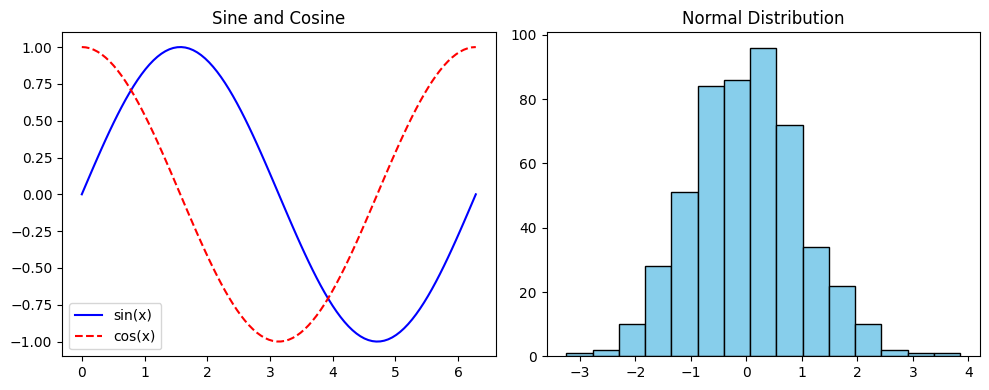

In [9]:
fig, axes = plot_signals_and_hist(x, samples)
plt.show()
